# 02. Sensor Sparsity & Missing Data Mechanics

> **Role**: Role 2 — Dataset Collection & EDA  
> **Project**: Project 18 — Water Quality Prediction via Gradient Boosting & DNN  
> **Course**: Semester 5 AML / DL  

Investigates missingness patterns across sensors and countries, classifies missingness mechanisms (MCAR vs MAR), and provides scientific recommendations for downstream imputation.

---

## 1. Setup & Environment

In [ ]:
# Setup & Load Data
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
df = pd.read_parquet(DATA_PATH)
chemical_cols = [
    'Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)',
    'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)',
    'pH (ph units)', 'Temperature (cel)', 'Nitrogen (mg/l)', 'Nitrate (mg/l)'
]
print(f"Loaded dataset with {len(df):,} rows.")

Loaded dataset with 4,297,895 rows.


## 2. Missing Value Audit per Parameter
Quantify missing counts and percentages across all 8 chemical sensors.

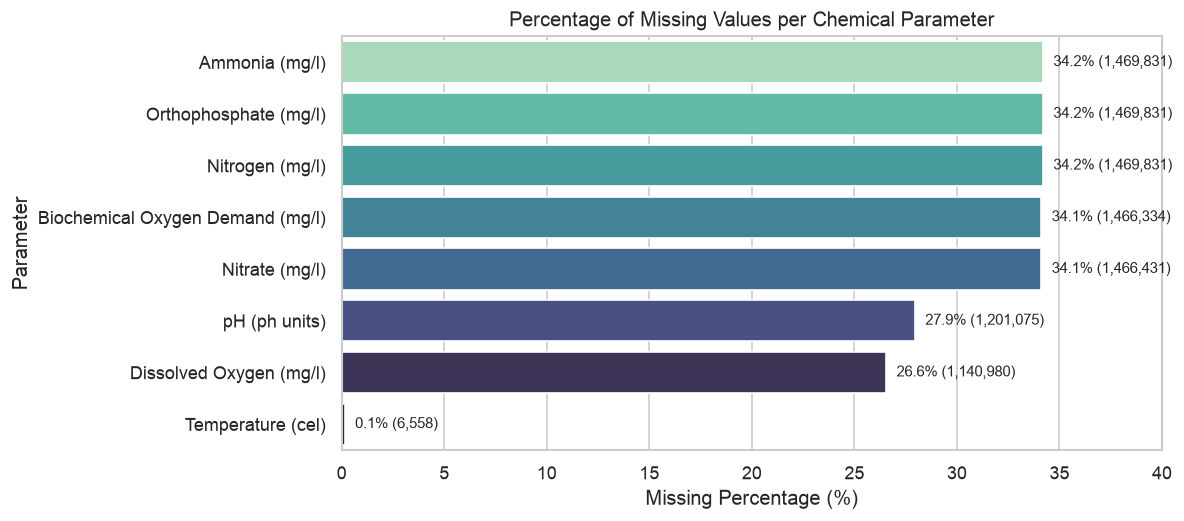

In [ ]:
# Missing Values Audit
null_counts = df[chemical_cols].isnull().sum()
null_pcts = (null_counts / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Parameter': chemical_cols,
    'Missing Count': null_counts.values,
    'Missing %': null_pcts.values,
    'Present Count': (len(df) - null_counts).values,
    'Present %': (100 - null_pcts).values
}).sort_values('Missing %', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(data=missing_df, x='Missing %', y='Parameter', palette='mako_r', hue='Parameter', legend=False)
plt.title('Percentage of Missing Values per Chemical Parameter')
plt.xlabel('Missing Percentage (%)')
plt.xlim(0, 40)

for i, p in enumerate(missing_df['Missing %']):
    ax.text(p + 0.5, i, f"{p:.1f}% ({missing_df['Missing Count'].iloc[i]:,})", va='center', fontsize=9)

plt.tight_layout()
plt.show()

missing_df

## 3. Country-by-Country Missingness Heatmap
Reveals the structural divergence between laboratory monitoring panels and continuous in-situ telemetry.

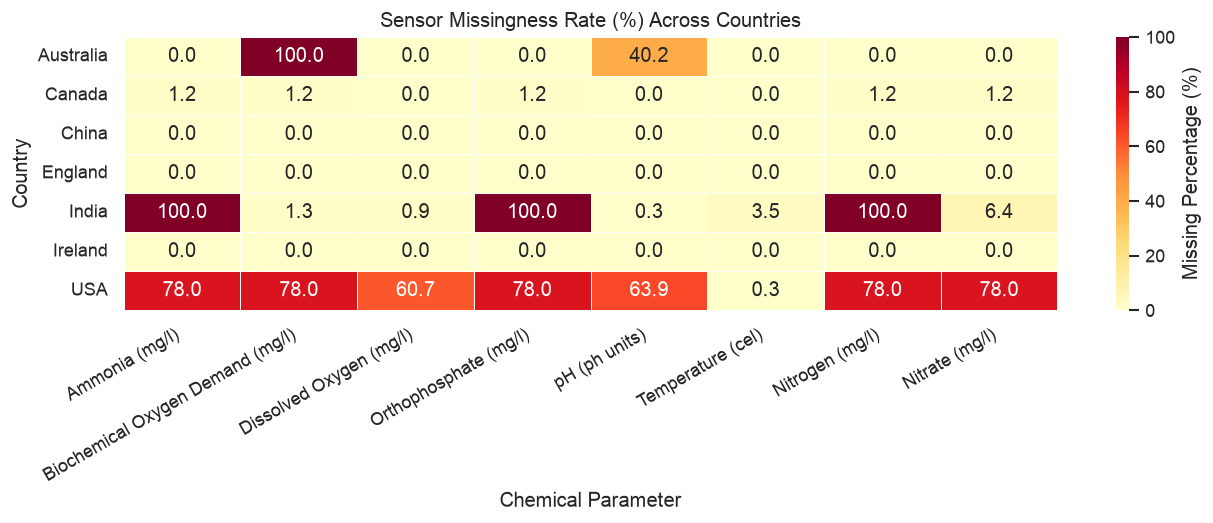

In [ ]:
# Country Missingness Matrix
country_missing = df.groupby('Country')[chemical_cols].apply(lambda g: (g.isnull().mean() * 100).round(1))

plt.figure(figsize=(11, 4.5))
sns.heatmap(country_missing, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Missing Percentage (%)'}, linewidths=0.5)
plt.title('Sensor Missingness Rate (%) Across Countries')
plt.xlabel('Chemical Parameter')
plt.ylabel('Country')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

country_missing

## 4. Sensor Co-Occurrence & Bundle Analysis
Analyzes whether sensors drop independently or in synchronized operational packets.

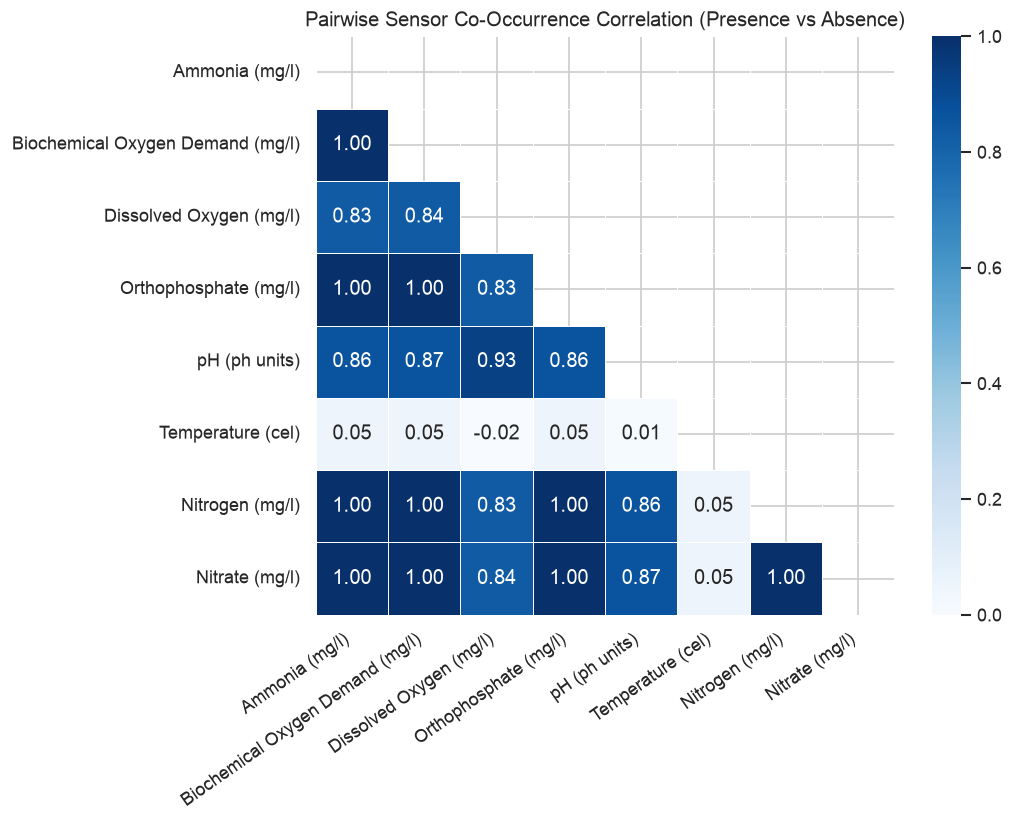

In [ ]:
# Sensor Co-Occurrence Matrix
presence_matrix = df[chemical_cols].notnull().astype(int)
co_occurrence = presence_matrix.corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(co_occurrence, dtype=bool))
sns.heatmap(co_occurrence, mask=mask, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True, linewidths=0.5)
plt.title('Pairwise Sensor Co-Occurrence Correlation (Presence vs Absence)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 5. Complete Panel vs Telemetry Subset Quantification
Quantifies complete-case availability across global records.

In [ ]:
# Complete Cases by Country
complete_mask = df[chemical_cols].notnull().all(axis=1)
complete_count = complete_mask.sum()
print(f"Total Complete-Case Records (All 8 Sensors Active): {complete_count:,} ({complete_count/len(df)*100:.2f}%)")

subset_summary = df.groupby('Country').apply(lambda g: pd.Series({
    'Total Records': len(g),
    'Complete Cases': g[chemical_cols].notnull().all(axis=1).sum(),
    'Complete %': (g[chemical_cols].notnull().all(axis=1).mean() * 100).round(2),
    'Physical Probe Only (Temp+pH+DO)': (g[['Temperature (cel)', 'pH (ph units)', 'Dissolved Oxygen (mg/l)']].notnull().all(axis=1)).sum()
})).reset_index()

subset_summary

Total Complete-Case Records (All 8 Sensors Active): 2,827,977 (65.80%)


## 6. Missingness Mechanism & Imputation Evaluation
Formal assessment of MCAR/MAR and recommendation for Role 3.

In [ ]:
# Export Missingness Data
imputation_advice = pd.DataFrame({
    'Subset': ['England / Ireland / China', 'USA Telemetry Stations', 'India CPCB Network'],
    'Mechanism': ['Complete Data (0% Missing)', 'Missing at Random (MAR) - Telemetry vs Lab', 'Missing at Random (MAR) - Sensor absence'],
    'Downstream Strategy': [
        'Ready for direct training (2.41M rows gold benchmark)',
        'KNN / Iterative Imputation or separate probe-only head',
        'Impute BOD/DO or utilize parameter subset models'
    ]
})

out_path = os.path.join(OUT_DIR, '02_missingness_patterns.parquet')
country_missing.reset_index().to_parquet(out_path, index=False, compression='snappy')
print(f"Exported Missingness Patterns to {out_path} ({os.path.getsize(out_path)} bytes)")
imputation_advice

Exported Missingness Patterns to data/GeneratedOutput/01.EDA/02_missingness_patterns.parquet (6571 bytes)
